<a href="https://colab.research.google.com/github/anitejpadyana/BIS-lab/blob/main/Parallel_Cell_Algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Optimal Landing Position: [9.50356944 8.85085212]
Minimum Landing Cost: 12.449768257005358


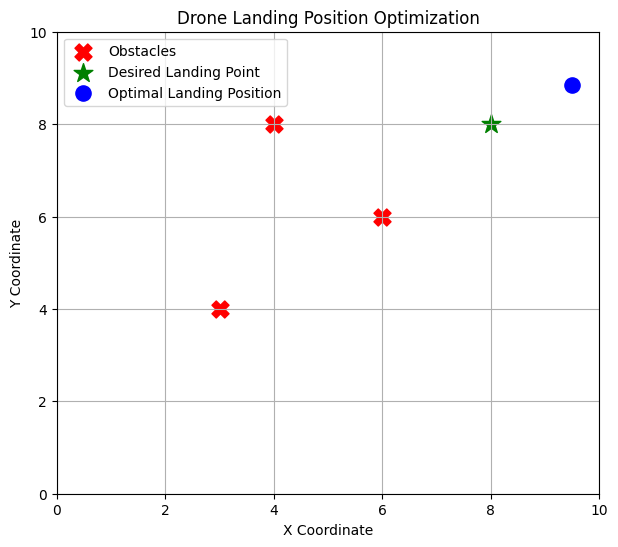

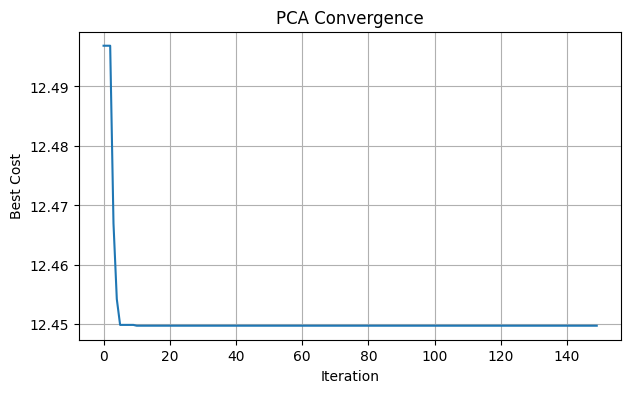

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

R, C = 6, 6
D = 2
MaxIter = 150
x_min, x_max = 0, 10

obstacles = np.array([
    [3, 4],
    [6, 6],
    [4, 8]
])

def objective(x):
    distance = np.sum((x - np.array([8, 8]))**2)
    penalty = 0

    for obs in obstacles:
        d = np.sum((x - obs)**2)
        penalty += 100 / (d + 0.5)

    return distance + penalty

grid = np.random.uniform(x_min, x_max, (R, C, D))
fitness = np.zeros((R, C))

for r in range(R):
    for c in range(C):
        fitness[r, c] = objective(grid[r, c])

def get_neighbors(r, c):
    neighbors = []

    for dr in [-1, 0, 1]:
        for dc in [-1, 0, 1]:
            if dr == 0 and dc == 0:
                continue

            nr = (r + dr) % R
            nc = (c + dc) % C
            neighbors.append((nr, nc))

    return neighbors

best_history = []

for iteration in range(MaxIter):
    next_grid = grid.copy()
    next_fitness = fitness.copy()

    for r in range(R):
        for c in range(C):

            neighbors = get_neighbors(r, c)

            best_neighbor = min(
                neighbors,
                key=lambda p: fitness[p[0], p[1]]
            )

            x_nb = grid[best_neighbor[0], best_neighbor[1]]

            rho = np.random.random()
            noise = np.random.normal(0, 0.1, D)

            x_new = grid[r, c] + rho * (x_nb - grid[r, c]) + noise
            x_new = np.clip(x_new, x_min, x_max)

            new_fitness = objective(x_new)

            if new_fitness < fitness[r, c]:
                next_grid[r, c] = x_new
                next_fitness[r, c] = new_fitness

    grid = next_grid
    fitness = next_fitness

    best_history.append(np.min(fitness))

best_index = np.unravel_index(np.argmin(fitness), fitness.shape)
best_position = grid[best_index]

print("Optimal Landing Position:", best_position)
print("Minimum Landing Cost:", fitness[best_index])

plt.figure(figsize=(7, 6))

plt.scatter(obstacles[:, 0], obstacles[:, 1],
            color='red', marker='X', s=150, label='Obstacles')

plt.scatter(8, 8, color='green', marker='*',
            s=200, label='Desired Landing Point')

plt.scatter(best_position[0], best_position[1],
            color='blue', marker='o', s=120,
            label='Optimal Landing Position')

plt.xlim(0, 10)
plt.ylim(0, 10)
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.title("Drone Landing Position Optimization")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(best_history)
plt.xlabel("Iteration")
plt.ylabel("Best Cost")
plt.title("PCA Convergence")
plt.grid()
plt.show()
